# Hafta 2 · Veriyi Modele Hazırlamak

**Ekonomi ve Finansta Makine Öğrenmesi** · Prof. Dr. Mehmet Songur · Dicle Üniversitesi

[![Colab'da aç](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mehmetsongur/Machine-Learning-in-Economics-and-Finance/blob/main/code/Hafta02_Veri_Hazirlama.ipynb)

**Haftanın konusu:** Öğrenme türleri, değişken ve hedef, veri türleri, veri hazırlama kavramları

Bu defter, Hafta 2 ders notundaki ve slaytlarındaki şu şekil ve tabloları üretir:

- **Ortak örnek tablo:** altı müşterilik kredi tablosu ve iki “kusuru” (ders notu, açılış ve 4.1)
- **Eksik veri:** medyanla doldurma ve eksiklik göstergesi (4.2)
- **Şekil 4:** Ölçeklemenin etkisi, A–B–C örneği (4.4)
- **Kukla değişkenler** (one-hot kodlama) (4.5) ve **oran türetme** (4.6)

Tüm sayılar yapay (simüle edilmiş) veriye dayanır. Rastgele sayı üreticisinin tohumu sabit olduğu için hücreler **yukarıdan aşağıya sırayla** çalıştırıldığında sonuçlar ders materyalindeki değerlerle birebir aynı çıkar. Hücreleri atlarsanız ya da sırasını değiştirirseniz sayılar biraz farklılaşabilir; yorumlar değişmez.

Slaytlar: [Hafta 2 (PDF)](https://www.songurmehmet.com/assets/dersler/ml/Hafta02_Slaytlar.pdf)  
Kod MIT lisansıyla paylaşılmıştır; ayrıntı için deponun `code/LICENSE` dosyasına bakın.

## 1. Ortak örnek tablo

Dersin başında kullanılan kurgusal tablo. İki kusur bilerek konmuştur: 4. müşterinin geliri eksik, 5. müşterinin kart harcaması olağandışı.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

tablo = pd.DataFrame({
    'musteri':       [1, 2, 3, 4, 5, 6],
    'yas':           [34, 51, 23, 45, 29, 62],
    'il':            ['Diyarbakır', 'İstanbul', 'Mersin', 'Ankara', 'Diyarbakır', 'İzmir'],
    'gelir':         [28000, 85000, 19500, np.nan, 32000, 41000],
    'kart_harcamasi':[9500, 31000, 12800, 7200, 268000, 5100],
    'onceki_gecikme':['Hayır', 'Hayır', 'Evet', 'Hayır', 'Evet', 'Hayır'],
    'temerrut':      ['Hayır', 'Hayır', 'Evet', 'Hayır', 'Hayır', 'Hayır'],
})
tablo

,musteri,yas,il,gelir,kart_harcamasi,onceki_gecikme,temerrut
0,1,34,Diyarbakır,28000.0,9500,Hayır,Hayır
1,2,51,İstanbul,85000.0,31000,Hayır,Hayır
2,3,23,Mersin,19500.0,12800,Evet,Evet
3,4,45,Ankara,NaN,7200,Hayır,Hayır
4,5,29,Diyarbakır,32000.0,268000,Evet,Hayır
5,6,62,İzmir,41000.0,5100,Hayır,Hayır


## 2. Önce veriyi tanı (keşifsel bakış)

Basit bir özet bile iki sorunu ortaya çıkarır: `gelir` sütununda bir eksik değer var; `kart_harcamasi` sütununun en büyük değeri diğerlerinden çok farklı.

In [2]:
print('Eksik değer sayıları:'); print(tablo.isna().sum()); print()
tablo[['yas', 'gelir', 'kart_harcamasi']].describe().round(0)

Eksik değer sayıları:
musteri           0
yas               0
il                0
gelir             1
kart_harcamasi    0
onceki_gecikme    0
temerrut          0
dtype: int64



,yas,gelir,kart_harcamasi
count,6.0,5.0,6.0
mean,41.0,41100.0,55600.0
std,15.0,25730.0,104469.0
min,23.0,19500.0,5100.0
25%,30.0,28000.0,7775.0
50%,40.0,32000.0,11150.0
75%,50.0,41000.0,26450.0
max,62.0,85000.0,268000.0


In [3]:
# Harcamanın gelire oranı: 5. müşterinin harcaması gelirinin yaklaşık 8 katı → hata mı, gerçek mi?
tablo['harcama_gelir_orani'] = (tablo['kart_harcamasi'] / tablo['gelir']).round(2)
tablo[['musteri', 'gelir', 'kart_harcamasi', 'harcama_gelir_orani']]

,musteri,gelir,kart_harcamasi,harcama_gelir_orani
0,1,28000.0,9500,0.34
1,2,85000.0,31000,0.36
2,3,19500.0,12800,0.66
3,4,NaN,7200,NaN
4,5,32000.0,268000,8.38
5,6,41000.0,5100,0.12


## 3. Eksik veri: doldurma ve eksiklik göstergesi

Ne yapılacağı, verinin **neden** eksik olduğuna bağlıdır (Rubin, 1976). Burada iki basit adımı gösteriyoruz: geliri medyanla doldurmak ve “gelir eksikti” bilgisini ayrı bir 0/1 sütununda saklamak. Gelirini beyan etmeyen başvuranın bu tercihi kendi başına bilgi taşıyabilir.

*Not:* Gerçek bir çalışmada medyan yalnızca eğitim verisinden hesaplanır; bu kural Hafta 3’te (veri sızıntısı) ele alınıyor.

In [4]:
hazir = tablo.copy()
hazir['gelir_eksik'] = hazir['gelir'].isna().astype(int)        # eksiklik göstergesi
hazir['gelir'] = hazir['gelir'].fillna(hazir['gelir'].median())  # medyanla doldurma
hazir[['musteri', 'gelir', 'gelir_eksik']]

,musteri,gelir,gelir_eksik
0,1,28000.0,0
1,2,85000.0,0
2,3,19500.0,0
3,4,32000.0,1
4,5,32000.0,0
5,6,41000.0,0


## 4. Ölçekleme: A kime benziyor? (Şekil 4)

A (25 yaş, 30.000 TL), B (60 yaş, 31.000 TL), C (26 yaş, 45.000 TL). Sezgimiz A’nın C’ye benzediğini söyler. Ham birimlerle hesaplanan uzaklıkta ise gelirin büyük birimi kararı ele geçirir.

In [5]:
kisi = {'A': (25, 30000), 'B': (60, 31000), 'C': (26, 45000)}
uzaklik = lambda p, q: np.hypot(p[0] - q[0], p[1] - q[1])

print('Ham birimlerle      A–B:', round(uzaklik(kisi['A'], kisi['B']), 1), '  A–C:', round(uzaklik(kisi['A'], kisi['C']), 1))

# Standartlaştırma: z = (x − ortalama) / standart sapma. Ders notundaki gibi yaş için s = 10, gelir için s = 10.000 alıyoruz.
z = {k: (v[0] / 10, v[1] / 10000) for k, v in kisi.items()}   # farklar alındığı için ortalamayı çıkarmak sonucu değiştirmez
print('Standartlaştırınca  A–B:', round(uzaklik(z['A'], z['B']), 2), '  A–C:', round(uzaklik(z['A'], z['C']), 2))

Ham birimlerle      A–B: 1000.6   A–C: 15000.0
Standartlaştırınca  A–B: 3.5   A–C: 1.5


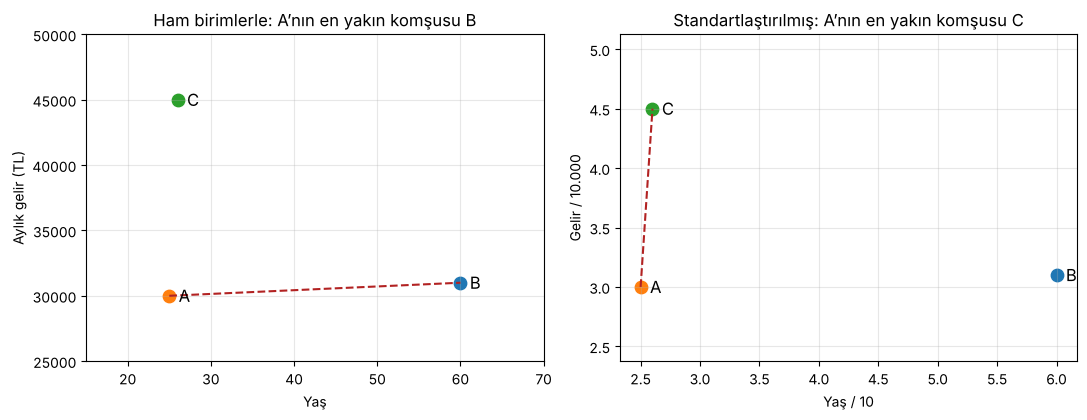

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4.3))
renk = {'A': 'tab:orange', 'B': 'tab:blue', 'C': 'tab:green'}
for ax, veri, baslik, yakin in [(axs[0], kisi, 'Ham birimlerle', 'B'), (axs[1], z, 'Standartlaştırılmış', 'C')]:
    for k, (x, y) in veri.items():
        ax.scatter(x, y, s=80, color=renk[k]); ax.annotate('  ' + k, (x, y), fontsize=12, va='center')
    ax.plot(*zip(veri['A'], veri[yakin]), '--', color='firebrick')
    ax.set_title(f'{baslik}: A’nın en yakın komşusu {yakin}'); ax.grid(alpha=0.3)
axs[0].set(xlabel='Yaş', ylabel='Aylık gelir (TL)', xlim=(15, 70), ylim=(25000, 50000))
axs[1].set(xlabel='Yaş / 10', ylabel='Gelir / 10.000'); axs[1].set_aspect('equal', adjustable='datalim')
plt.tight_layout(); plt.show()

## 5. Kategorik değişkenler: kukla değişkenler (one-hot kodlama)

Algoritma “Diyarbakır” kelimesini anlamaz. Her il için bir 0/1 sütunu açılır; bu, ekonometrideki kukla değişkenlerin aynısıdır. Doğrusal regresyonda kukla tuzağına düşmemek için bir kategori dışarıda bırakılır (`drop_first=True`).

In [7]:
pd.get_dummies(tablo[['musteri', 'il']], columns=['il'], prefix='il', dtype=int)

,musteri,il_Ankara,il_Diyarbakır,il_Mersin,il_İstanbul,il_İzmir
0,1,0,1,0,0,0
1,2,0,0,0,1,0
2,3,0,0,1,0,0
3,4,1,0,0,0,0
4,5,0,1,0,0,0
5,6,0,0,0,0,1


In [8]:
# Kukla tuzağından kaçınmak için bir kategoriyi referans olarak dışarıda bırakmak
pd.get_dummies(tablo[['musteri', 'il']], columns=['il'], prefix='il', dtype=int, drop_first=True)

,musteri,il_Diyarbakır,il_Mersin,il_İstanbul,il_İzmir
0,1,1,0,0,0
1,2,0,0,1,0
2,3,0,1,0,0
3,4,0,0,0,0
4,5,1,0,0,0
5,6,0,0,0,1
